<h1 style="background-color: gray;
           color: black;
           padding: 20px;
           text-align: center;">INFO</h1>

In this script, we compare players `Random1`, `Random2` and `Random3` in a game where there is only one cheese to catch in a maze without mud. \
All programs are evaluated on the same game configurations. \
We do not show the game interface here, to make the script faster. \
The goal is to compare the performances of the different random players in the same conditions.

<h1 style="background-color: gray;
           color: black;
           padding: 20px;
           text-align: center;">IMPORTS</h1>

In [2]:
# External imports
import sys
import os
import tqdm.auto as tqdm
import matplotlib.pyplot as pyplot
import scipy.stats as scstats
import numpy as np

# Add needed directories to the path
sys.path.append(os.path.join("..", "players"))

# PyRat imports
from pyrat import Game, GameMode
from Exhaustive import Exhaustive
from Greedy import Greedy

C:\Users\natha\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<h1 style="background-color: gray;
           color: black;
           padding: 20px;
           text-align: center;">CONSTANTS</h1>

In this script, we are going to make multiple independent games. \
The goal is to collect enough statistics to draw conclusions on which algorithm is better than the other. \
This constant defines how many games are made.

In [1]:
# Determines how many games will be played for each player
NB_GAMES = 50
CHEESES = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

Let's configure the game with a dictionary. \
Note that we put the game mode as `SIMULATION` to perform all games as fast as possible.

In [4]:
# Customize the game elements
CONFIG = {"mud_percentage": 20.0,
          "game_mode": GameMode.SIMULATION}

<h1 style="background-color: gray;
           color: black;
           padding: 20px;
           text-align: center;">RUN THE GAMES</h1>

Let us now perform all games. \
For each game, we remember the number of turns needed to complete it.

In [5]:
# Players to test (keys are legends to appear in the plot)
players = {"Exhaustive": {"class": Exhaustive, "args": {}},
           "Greedy": {"class": Greedy, "args": {}}}

# Run the games for each player
results = {player: [[]for i in range(len(CHEESES))] for player in players}
preproc_duration = {player: [[]for i in range(len(CHEESES))] for player in players}

for key in players:
    for i in range(len(CHEESES)):
        for seed in tqdm.tqdm(range(NB_GAMES), desc=key):
            # Make the game with given seed
            game = Game(random_seed=seed, nb_cheese=CHEESES[i], **CONFIG)
            player = players[key]["class"](**players[key]["args"])
            game.add_player(player)
            stats = game.start()
            # Store the number of turns needed
            results[key][i].append(stats["turns"])
            preproc_duration[key][i].append(stats["players"][key]['preprocessing_duration'])

Greedy: 100%|██████████| 50/50 [00:06<00:00,  7.50it/s]


<h1 style="background-color: gray;
           color: black;
           padding: 20px;
           text-align: center;">ANALYZE THE RESULTS</h1>
           
Now that all games are performed, we plot the number of turns needed to catch all cheeses as a function of the amount of cheese on the map.

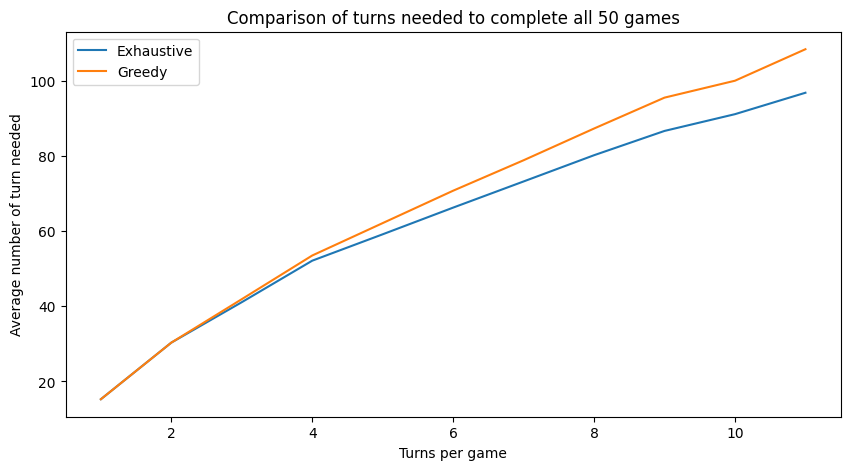

In [6]:
# Visualization of cumulative curves of numbers of turns taken per program
max_turn = max([max(results[player]) for player in results])
pyplot.figure(figsize=(10, 5))
for player in results:
    turns = [0] + sorted(results[player]) + [max_turn]
    avg_turn_per_cheese = [np.mean(results[player][i]) for i in range(len(CHEESES))]
    pyplot.plot(CHEESES, avg_turn_per_cheese, label=player)
pyplot.title("Comparison of turns needed to complete all %d games" % (NB_GAMES))
pyplot.xlabel("Turns per game")
pyplot.ylabel("Average number of turn needed")
pyplot.legend() 
pyplot.show()

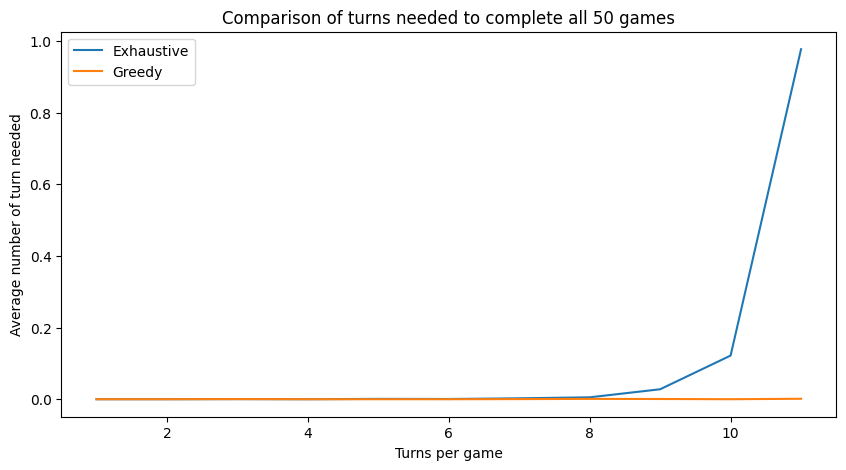

In [ ]:
# Visualization of cumulative curves of numbers of turns taken per program
max_turn = max([max(results[player]) for player in results])
pyplot.figure(figsize=(10, 5))
for player in results:
    turns = [0] + sorted(results[player]) + [max_turn]
    avg_preprocessing_time_per_cheese = [np.mean(preproc_duration[player][i]) for i in range(len(CHEESES))]
    pyplot.plot(CHEESES, avg_preprocessing_time_per_cheese, label=player)
pyplot.title("Comparison of turns needed to complete all %d games" % (NB_GAMES))
pyplot.xlabel("Turns per game")
pyplot.ylabel("Average preprocessing time")
pyplot.legend() 
pyplot.show()

Visualizing is great, but it may be hard to conclude with just a plot. \
Here, we perform a statistical test that will give more insight on whether an algorithm is better than the other.

In [7]:
# Formal statistics to check if these curves are statistically significant
for i, player_1 in enumerate(results):
    for j, player_2 in enumerate(results):
        if j > i:
            test_result = scstats.mannwhitneyu(results[player_1], results[player_2], alternative="two-sided")
            print("Mann-Whitney U test between turns of program '%s' and of program '%s':" % (player_1, player_2), test_result)

Mann-Whitney U test between turns of program 'Exhaustive' and of program 'Greedy': MannwhitneyuResult(statistic=array([33. , 47. , 54.5, 51. , 58. , 46. , 53. , 52. , 51.5, 49.5, 44. ,
       60.5, 46.5, 41. , 53.5, 48. , 54. , 55. , 51.5, 46.5, 53. , 39. ,
       54.5, 52. , 52.5, 55.5, 55. , 46.5, 56. , 50.5, 48.5, 57.5, 54.5,
       52.5, 55.5, 60. , 49.5, 49. , 60.5, 53. , 60.5, 51. , 47.5, 45. ,
       53.5, 55. , 55.5, 50. , 50.5, 54. ]), pvalue=array([0.07515807, 0.38979943, 0.71659964, 0.55329557, 0.89014029,
       0.35451443, 0.64501616, 0.59696859, 0.57598501, 0.48941394,
       0.29150871, 1.        , 0.37155223, 0.20905221, 0.66791718,
       0.42755982, 0.69226589, 0.74217394, 0.57489918, 0.37427903,
       0.64188136, 0.16234428, 0.71659964, 0.59453328, 0.62089199,
       0.76672039, 0.74203287, 0.37251052, 0.79183398, 0.53193554,
       0.44964808, 0.86942039, 0.71729318, 0.6195928 , 0.76509198,
       1.        , 0.48817704, 0.46909515, 1.        , 0.64407491,
       1